In [3]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
import seaborn as sns
train_df=pd.read_csv("Spaceship/train.csv")

In [4]:
!git clone https://github.com/folkstay/Spaceship.git

fatal: destination path 'Spaceship' already exists and is not an empty directory.


In [5]:
train_df.head()

,PassengerId,HomePlanet,CryoSleep,Cabin,Destination,Age,VIP,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,Name,Transported
0,0001_01,Europa,False,B/0/P,TRAPPIST-1e,39.0,False,0.0,0.0,0.0,0.0,0.0,Maham Ofracculy,False
1,0002_01,Earth,False,F/0/S,TRAPPIST-1e,24.0,False,109.0,9.0,25.0,549.0,44.0,Juanna Vines,True
2,0003_01,Europa,False,A/0/S,TRAPPIST-1e,58.0,True,43.0,3576.0,0.0,6715.0,49.0,Altark Susent,False
3,0003_02,Europa,False,A/0/S,TRAPPIST-1e,33.0,False,0.0,1283.0,371.0,3329.0,193.0,Solam Susent,False
4,0004_01,Earth,False,F/1/S,TRAPPIST-1e,16.0,False,303.0,70.0,151.0,565.0,2.0,Willy Santantines,True


In [6]:
train_df.isna().sum()

,0
PassengerId,0
HomePlanet,201
CryoSleep,217
Cabin,199
Destination,182
Age,179
VIP,203
RoomService,181
FoodCourt,183
ShoppingMall,208


In [7]:
cat_features = ["HomePlanet", "CryoSleep", "Destination", "VIP"]
num_features = ["Age", "RoomService", "FoodCourt", "ShoppingMall", "Spa", "VRDeck"]

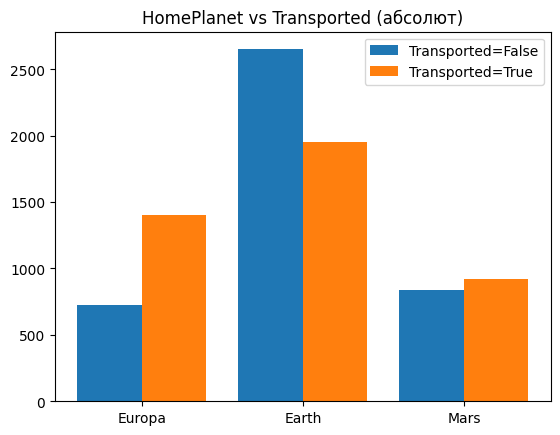

In [8]:
planets = train_df["HomePlanet"].dropna().unique()
x = np.arange(len(planets))
width = 0.4

for i, val in enumerate([False, True]):
    counts = [len(train_df[(train_df["HomePlanet"] == p) & (train_df["Transported"] == val)]) for p in planets]
    plt.bar(x + i * width, counts, width, label=f"Transported={val}")

plt.xticks(x + width / 2, planets)
plt.title("HomePlanet vs Transported (абсолют)")
plt.legend()
plt.show()
#Вывод: Планета влияет

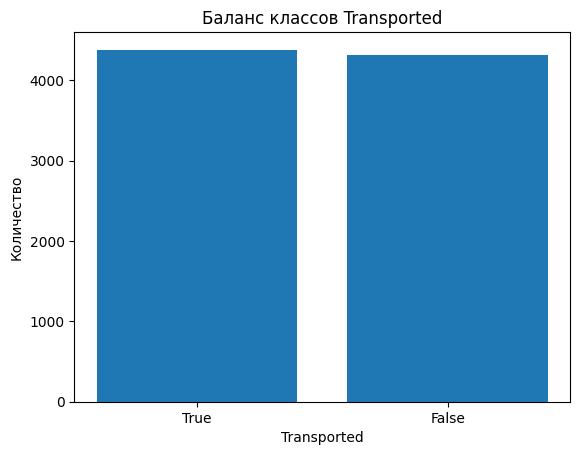

In [9]:
counts = train_df["Transported"].value_counts()
plt.bar(counts.index.astype(str), counts.values)
plt.title("Баланс классов Transported")
plt.xlabel("Transported")
plt.ylabel("Количество")
plt.show()

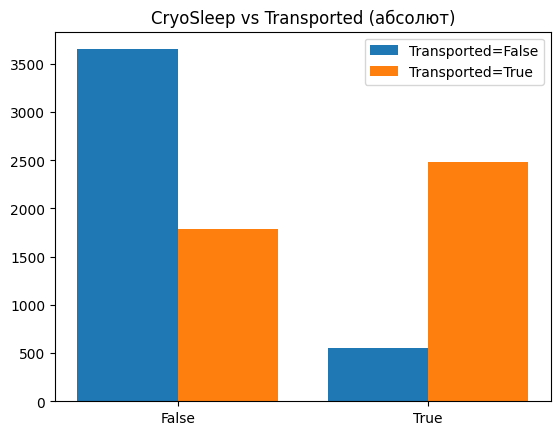

In [10]:
planets = train_df["CryoSleep"].dropna().unique()
x = np.arange(len(planets))
width = 0.4

for i, val in enumerate([False, True]):
    counts = [len(train_df[(train_df["CryoSleep"] == p) & (train_df["Transported"] == val)]) for p in planets]
    plt.bar(x + i * width, counts, width, label=f"Transported={val}")

plt.xticks(x + width / 2, planets)
plt.title("CryoSleep vs Transported (абсолют)")
plt.legend()
plt.show()
#Вывод: сон очень влияет

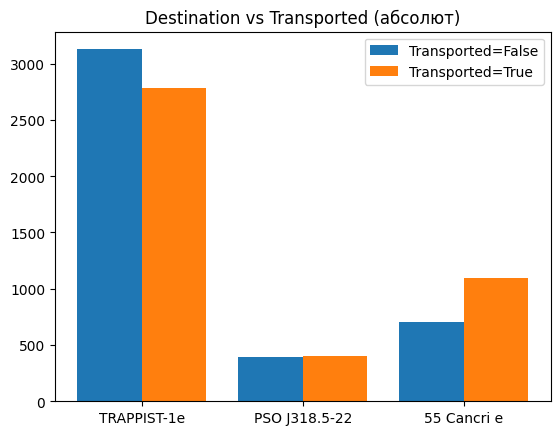

In [11]:
planets = train_df["Destination"].dropna().unique()
x = np.arange(len(planets))
width = 0.4

for i, val in enumerate([False, True]):
    counts = [len(train_df[(train_df["Destination"] == p) & (train_df["Transported"] == val)]) for p in planets]
    plt.bar(x + i * width, counts, width, label=f"Transported={val}")

plt.xticks(x + width / 2, planets)
plt.title("Destination vs Transported (абсолют)")
plt.legend()
plt.show()
#Вывод: почти не влияет

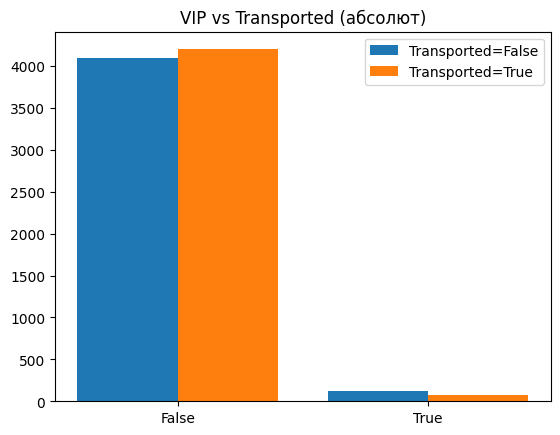

In [12]:
planets = train_df["VIP"].dropna().unique()
x = np.arange(len(planets))
width = 0.4

for i, val in enumerate([False, True]):
    counts = [len(train_df[(train_df["VIP"] == p) & (train_df["Transported"] == val)]) for p in planets]
    plt.bar(x + i * width, counts, width, label=f"Transported={val}")

plt.xticks(x + width / 2, planets)
plt.title("VIP vs Transported (абсолют)")
plt.legend()
plt.show()
#Вывод: Очень слабо влияет

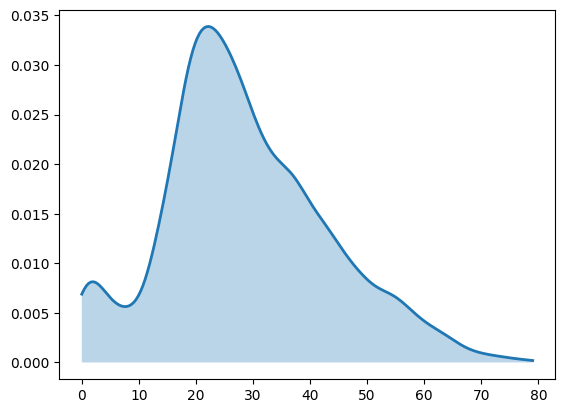

In [13]:
from scipy.stats import gaussian_kde
import numpy as np

data = train_df["Age"].dropna()
kde = gaussian_kde(data)
x = np.linspace(data.min(), data.max(), 200)
plt.plot(x, kde(x), linewidth=2)
plt.fill_between(x, kde(x), alpha=0.3)

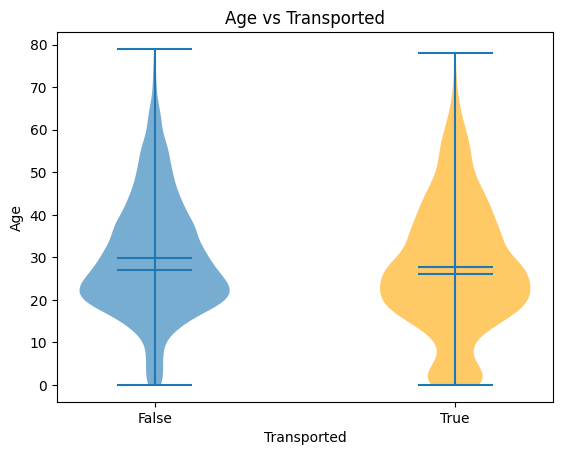

In [14]:
ages_false = train_df[train_df["Transported"] == False]["Age"].dropna()
ages_true  = train_df[train_df["Transported"] == True ]["Age"].dropna()
parts = plt.violinplot(
    [ages_false, ages_true],
    positions=[0, 1],
    showmeans=True,
    showmedians=True,
)
for body, color in zip(parts["bodies"], ["C0", "orange"]):
    body.set_facecolor(color)
    body.set_alpha(0.6)

plt.xticks([0, 1], ["False", "True"])
plt.xlabel("Transported")
plt.ylabel("Age")
plt.title("Age vs Transported")
plt.show()

In [15]:
# Целевая → 0/1
train_df["Transported_int"] = train_df["Transported"].astype(int)

# Корреляция числовых признаков с целевой
num_cols = ["Age", "RoomService", "FoodCourt", "ShoppingMall", "Spa", "VRDeck", "Transported_int"]
corr_with_target = train_df[num_cols].corr()["Transported_int"].sort_values()
print(corr_with_target)

RoomService       -0.244611
Spa               -0.221131
VRDeck            -0.207075
Age               -0.075026
ShoppingMall       0.010141
FoodCourt          0.046566
Transported_int    1.000000
Name: Transported_int, dtype: float64


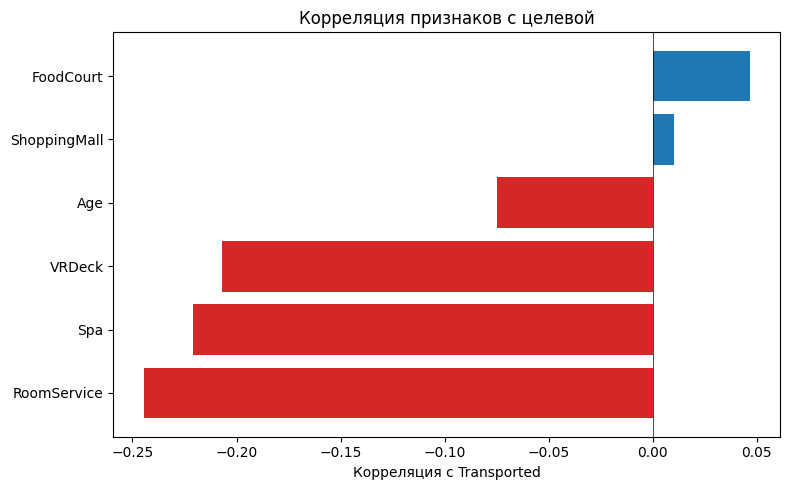

In [16]:
corr_target = train_df[num_cols].corr()["Transported_int"].drop("Transported_int").sort_values()

plt.figure(figsize=(8, 5))
colors = ["C3" if v < 0 else "C0" for v in corr_target.values]
plt.barh(corr_target.index, corr_target.values, color=colors)
plt.axvline(0, color="black", linewidth=0.5)
plt.xlabel("Корреляция с Transported")
plt.title("Корреляция признаков с целевой")
plt.tight_layout()
plt.show()

In [17]:

train_df["Group"] = train_df["PassengerId"].str.split("_").str[0].astype(int)

train_df = train_df.drop(['PassengerId','Name'], axis=1)
train_df['Transported'] = train_df['Transported'].astype(int)
train_df = train_df.drop(['Transported_int'], axis=1)
train_df.head(5)

,HomePlanet,CryoSleep,Cabin,Destination,Age,VIP,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,Transported,Group
0,Europa,False,B/0/P,TRAPPIST-1e,39.0,False,0.0,0.0,0.0,0.0,0.0,0,1
1,Earth,False,F/0/S,TRAPPIST-1e,24.0,False,109.0,9.0,25.0,549.0,44.0,1,2
2,Europa,False,A/0/S,TRAPPIST-1e,58.0,True,43.0,3576.0,0.0,6715.0,49.0,0,3
3,Europa,False,A/0/S,TRAPPIST-1e,33.0,False,0.0,1283.0,371.0,3329.0,193.0,0,3
4,Earth,False,F/1/S,TRAPPIST-1e,16.0,False,303.0,70.0,151.0,565.0,2.0,1,4


In [18]:
train_df=train_df.drop(['VIP', 'Destination'], axis=1)
train_df.head(5)

,HomePlanet,CryoSleep,Cabin,Age,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,Transported,Group
0,Europa,False,B/0/P,39.0,0.0,0.0,0.0,0.0,0.0,0,1
1,Earth,False,F/0/S,24.0,109.0,9.0,25.0,549.0,44.0,1,2
2,Europa,False,A/0/S,58.0,43.0,3576.0,0.0,6715.0,49.0,0,3
3,Europa,False,A/0/S,33.0,0.0,1283.0,371.0,3329.0,193.0,0,3
4,Earth,False,F/1/S,16.0,303.0,70.0,151.0,565.0,2.0,1,4


In [19]:
train_df[["Deck", "Cabin_num", "Side"]] = train_df["Cabin"].str.split("/", expand=True)
train_df["Cabin_num"] = pd.to_numeric(train_df["Cabin_num"])
train_df.head(5)

,HomePlanet,CryoSleep,Cabin,Age,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,Transported,Group,Deck,Cabin_num,Side
0,Europa,False,B/0/P,39.0,0.0,0.0,0.0,0.0,0.0,0,1,B,0.0,P
1,Earth,False,F/0/S,24.0,109.0,9.0,25.0,549.0,44.0,1,2,F,0.0,S
2,Europa,False,A/0/S,58.0,43.0,3576.0,0.0,6715.0,49.0,0,3,A,0.0,S
3,Europa,False,A/0/S,33.0,0.0,1283.0,371.0,3329.0,193.0,0,3,A,0.0,S
4,Earth,False,F/1/S,16.0,303.0,70.0,151.0,565.0,2.0,1,4,F,1.0,S


In [20]:
try:
    train_df = train_df.drop('Cabin', axis=1)
except KeyError:
    print("Field does not exist")

In [21]:
#Список колонок с тратами
spend_cols = ['RoomService', 'FoodCourt', 'ShoppingMall', 'Spa', 'VRDeck']

#Создаём колонку с суммой всех трат
train_df['TotalSpend'] = train_df[spend_cols].sum(axis=1)

# Удаляем исходные колонки трат
#train_df = train_df.drop(columns=spend_cols)

#train_df.head()

In [22]:
#The SimpleImputer class provides basic strategies for imputing missing values.
from sklearn.impute import SimpleImputer

In [23]:
for col in ["HomePlanet", "Deck", "Side", "Cabin_num"]:
    train_df[col] = train_df[col].fillna(train_df.groupby("Group")[col].transform("first"))

cryo = train_df["CryoSleep"].astype(float)
asleep = cryo == 1
train_df.loc[asleep, spend_cols] = train_df.loc[asleep, spend_cols].fillna(0)
spend_sum = train_df[spend_cols].sum(axis=1)
all_known = train_df[spend_cols].notna().all(axis=1)
miss = cryo.isna()
cryo[miss & (spend_sum > 0)] = 0.0
cryo[miss & all_known & (spend_sum == 0)] = 1.0
train_df["CryoSleep"] = cryo

train_df[spend_cols] = train_df[spend_cols].fillna(0)
train_df["TotalSpend"] = train_df[spend_cols].sum(axis=1)
train_df["NoSpend"] = (train_df["TotalSpend"] == 0).astype(int)

model_num = ["Age"] + spend_cols + ["Cabin_num", "CryoSleep", "TotalSpend", "NoSpend"]
train_df[model_num] = train_df[model_num].fillna(train_df[model_num].median())

for col in ["HomePlanet", "Side", "Deck"]:
    train_df[col] = train_df[col].fillna(train_df[col].mode()[0])

In [24]:
train_df.isna().sum()

,0
HomePlanet,0
CryoSleep,0
Age,0
RoomService,0
FoodCourt,0
ShoppingMall,0
Spa,0
VRDeck,0
Transported,0
Group,0


In [25]:
train_df = pd.get_dummies(train_df, columns=["HomePlanet", "Side"], dtype=int)
train_df["CryoSleep"] = train_df["CryoSleep"].astype(int)

In [26]:
train_df.head()

,CryoSleep,Age,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,Transported,Group,Deck,Cabin_num,TotalSpend,NoSpend,HomePlanet_Earth,HomePlanet_Europa,HomePlanet_Mars,Side_P,Side_S
0,0,39.0,0.0,0.0,0.0,0.0,0.0,0,1,B,0.0,0.0,1,0,1,0,1,0
1,0,24.0,109.0,9.0,25.0,549.0,44.0,1,2,F,0.0,736.0,0,1,0,0,0,1
2,0,58.0,43.0,3576.0,0.0,6715.0,49.0,0,3,A,0.0,10383.0,0,0,1,0,0,1
3,0,33.0,0.0,1283.0,371.0,3329.0,193.0,0,3,A,0.0,5176.0,0,0,1,0,0,1
4,0,16.0,303.0,70.0,151.0,565.0,2.0,1,4,F,1.0,1091.0,0,1,0,0,0,1


In [27]:
from sklearn.preprocessing import OrdinalEncoder
encoder = OrdinalEncoder()
train_df["Deck_encoded"] = encoder.fit_transform(train_df[["Deck"]])

In [28]:
train_df=train_df.drop(columns=["Deck"])
train_df.head()

,CryoSleep,Age,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,Transported,Group,Cabin_num,TotalSpend,NoSpend,HomePlanet_Earth,HomePlanet_Europa,HomePlanet_Mars,Side_P,Side_S,Deck_encoded
0,0,39.0,0.0,0.0,0.0,0.0,0.0,0,1,0.0,0.0,1,0,1,0,1,0,1.0
1,0,24.0,109.0,9.0,25.0,549.0,44.0,1,2,0.0,736.0,0,1,0,0,0,1,5.0
2,0,58.0,43.0,3576.0,0.0,6715.0,49.0,0,3,0.0,10383.0,0,0,1,0,0,1,0.0
3,0,33.0,0.0,1283.0,371.0,3329.0,193.0,0,3,0.0,5176.0,0,0,1,0,0,1,0.0
4,0,16.0,303.0,70.0,151.0,565.0,2.0,1,4,1.0,1091.0,0,1,0,0,0,1,5.0


In [54]:
import copy
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import TensorDataset, DataLoader
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

torch.manual_seed(67)
np.random.seed(67)

# 1. Загрузка и подготовка признаков
train_raw = pd.read_csv("Spaceship/train.csv")
test_raw  = pd.read_csv("Spaceship/test.csv")
sub       = pd.read_csv("Spaceship/sample_submission.csv")

SPEND = ["RoomService", "FoodCourt", "ShoppingMall", "Spa", "VRDeck"]

def prepare(df):
    df = df.copy()
    df["Group"] = df["PassengerId"].str.split("_").str[0].astype(int)
    df[["Deck", "Cabin_num", "Side"]] = df["Cabin"].str.split("/", expand=True)
    df["Cabin_num"] = pd.to_numeric(df["Cabin_num"])

    for col in ["HomePlanet", "Deck", "Side", "Cabin_num"]:
        df[col] = df[col].fillna(df.groupby("Group")[col].transform("first"))

    cryo = df["CryoSleep"].astype(float)
    asleep = cryo == 1
    df.loc[asleep, SPEND] = df.loc[asleep, SPEND].fillna(0)
    spend_sum = df[SPEND].sum(axis=1)
    all_known = df[SPEND].notna().all(axis=1)
    miss = cryo.isna()
    cryo[miss & (spend_sum > 0)] = 0.0
    cryo[miss & all_known & (spend_sum == 0)] = 1.0
    df["CryoSleep"] = cryo

    df[SPEND] = df[SPEND].fillna(0)
    df["TotalSpend"] = df[SPEND].sum(axis=1)
    df["NoSpend"] = (df["TotalSpend"] == 0).astype(int)

    for col in SPEND + ["TotalSpend"]:
        df[col] = np.log1p(df[col])

    return df.drop(columns=["PassengerId", "Name", "Cabin", "VIP", "Destination", "Group"],
                   errors="ignore")

X = prepare(train_raw.drop(columns=["Transported"]))
y = train_raw["Transported"].astype(int).values
groups = train_raw["PassengerId"].str.split("_").str[0].astype(int).values
X_submit_raw = prepare(test_raw)

num_cols = ["Age", "RoomService", "FoodCourt", "ShoppingMall",
            "Spa", "VRDeck", "Cabin_num", "CryoSleep",
            "TotalSpend", "NoSpend"]

# 2. Архитектура MLP
class SpaceshipSolver(nn.Module):
    def __init__(self, input_size, hidden1=128, hidden2=64, output_size=2):
        super().__init__()
        self.fc1 = nn.Linear(input_size, hidden1)
        self.drop1 = nn.Dropout(0.35)
        self.fc2 = nn.Linear(hidden1, hidden2)
        self.drop2 = nn.Dropout(0.35)
        self.fc3 = nn.Linear(hidden2, output_size)

    def forward(self, x):
        x = F.gelu(self.fc1(x))
        x = self.drop1(x)
        x = F.gelu(self.fc2(x))
        x = self.drop2(x)
        return self.fc3(x)

# 3. Кросс-валидация на 5 фолдов
cv = StratifiedGroupKFold(n_splits=15, shuffle=True, random_state=0)
fold_accuracies = []
test_probs_all_folds = np.zeros((len(X_submit_raw), 2)) #вероятности со всех фолдов

epochs = 50
print("--- Старт 5-фолдовой кросс-валидации MLP ---")

for fold, (train_idx, val_idx) in enumerate(cv.split(X, y, groups)):
    # Делим таблицу на текущий трейн и валидацию
    X_train_df, y_train = X.iloc[train_idx], y[train_idx]
    X_val_df, y_val     = X.iloc[val_idx], y[val_idx]

    # создаем и обучаем скейлер
    preprocess = ColumnTransformer([
        ("num", Pipeline([
            ("imp", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler()),
        ]), num_cols),
        ("cat", Pipeline([
            ("imp", SimpleImputer(strategy="most_frequent")),
            ("ohe", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
        ]), ["HomePlanet", "Side", "Deck"]),
    ])

    X_train_np = preprocess.fit_transform(X_train_df)
    X_val_np   = preprocess.transform(X_val_df)
    X_sub_np   = preprocess.transform(X_submit_raw)

    train_loader = DataLoader(
        TensorDataset(torch.tensor(X_train_np, dtype=torch.float32), torch.tensor(y_train, dtype=torch.long)),
        batch_size=128, shuffle=True
    )
    val_loader = DataLoader(
        TensorDataset(torch.tensor(X_val_np, dtype=torch.float32), torch.tensor(y_val, dtype=torch.long)),
        batch_size=128, shuffle=False
    )

    # Создаем НОВУЮ модель и оптимизатор для текущего фолда
    torch.manual_seed(67 + fold)
    model = SpaceshipSolver(input_size=X_train_np.shape[1])
    optimizer = torch.optim.Adam(model.parameters(), lr=0.005, weight_decay=1e-4)
    criterion = nn.CrossEntropyLoss()

    best_val_acc = 0.0
    best_weights = None

    for epoch in range(epochs):
        model.train()
        for X_batch, y_batch in train_loader:
            optimizer.zero_grad()
            loss = criterion(model(X_batch), y_batch)
            loss.backward()
            optimizer.step()

        # Проверяем качество на валидации после каждой эпохи и запоминаем лучшие веса
        model.eval()
        correct_val, total_val = 0, 0
        with torch.no_grad():
            for X_val_batch, y_val_batch in val_loader:
                outputs = model(X_val_batch)
                _, predicted = torch.max(outputs, 1)
                total_val += y_val_batch.size(0)
                correct_val += (predicted == y_val_batch).sum().item()

        val_acc = correct_val / total_val
        if val_acc > best_val_acc:
            best_val_acc = val_acc
            best_weights = copy.deepcopy(model.state_dict())

    fold_accuracies.append(best_val_acc)
    print(f"Фолд {fold + 1} | Лучшая точность (Val Acc): {best_val_acc:.4f}")

    # Загружаем лучшие веса фолда и делаем прогноз вероятностей для test.csv
    model.load_state_dict(best_weights)
    model.eval()
    with torch.no_grad():
        X_sub_tensor = torch.tensor(X_sub_np, dtype=torch.float32)
        probs = F.softmax(model(X_sub_tensor), dim=1).numpy()
        test_probs_all_folds += probs / cv.n_splits

print("=" * 45)
print(f"Итоговая CV точность MLP: {np.mean(fold_accuracies):.4f} ± {np.std(fold_accuracies):.4f}")

# 4. Сохраняем сабмит по усредненным вероятностям всех 5 фолдов
final_preds = np.argmax(test_probs_all_folds, axis=1)
sub["Transported"] = final_preds.astype(bool)
sub["PassengerId"] = test_raw["PassengerId"]
sub.to_csv("submission_pytorch_cv.csv", index=False)
print(sub["Transported"].value_counts())


--- Старт 5-фолдовой кросс-валидации MLP ---
Фолд 1 | Лучшая точность (Val Acc): 0.8068
Фолд 2 | Лучшая точность (Val Acc): 0.8136
Фолд 3 | Лучшая точность (Val Acc): 0.8400
Фолд 4 | Лучшая точность (Val Acc): 0.8330
Фолд 5 | Лучшая точность (Val Acc): 0.8365
Фолд 6 | Лучшая точность (Val Acc): 0.8096
Фолд 7 | Лучшая точность (Val Acc): 0.8220
Фолд 8 | Лучшая точность (Val Acc): 0.7742
Фолд 9 | Лучшая точность (Val Acc): 0.8185
Фолд 10 | Лучшая точность (Val Acc): 0.8375
Фолд 11 | Лучшая точность (Val Acc): 0.8192
Фолд 12 | Лучшая точность (Val Acc): 0.8537
Фолд 13 | Лучшая точность (Val Acc): 0.8142
Фолд 14 | Лучшая точность (Val Acc): 0.8286
Фолд 15 | Лучшая точность (Val Acc): 0.8188
Итоговая CV точность MLP: 0.8217 ± 0.0178
Transported
True     2196
False    2081
Name: count, dtype: int64


In [30]:
#1)                  score
#Трейн Acc: 80.66% - 0.79074
#True     2145
#False    2132

#2) Увеличено количество нейронов (128, 64)
#Трейн Acc: 81.95% - 0.79518
#False    2175
#True     2102

#3) 3 Слоя вместо двух
#Трейн Acc: 80.59%
#True     2230
#False    2047

#4)Кросс валидация чета ничего не добавила странно
# Фолд 1 | Лучшая точность (Val Acc): 0.8114
# Фолд 2 | Лучшая точность (Val Acc): 0.7946
# Фолд 3 | Лучшая точность (Val Acc): 0.8145
# Фолд 4 | Лучшая точность (Val Acc): 0.7938
# Фолд 5 | Лучшая точность (Val Acc): 0.8231
# =============================================
# Итоговая CV точность MLP: 0.8075 ± 0.0115

#5)silu Итоговая CV точность MLP: 0.8044 ± 0.0100

#6)Итоговая CV точность MLP: 0.8070 ± 0.0112
#        self.drop1 = nn.Dropout(0.1)
#        self.drop2 = nn.Dropout(0.1)

#7) Итоговая CV точность MLP: 0.8104 ± 0.0109
#lr=0.001 -> lr=0.005

#8)lr=0.005 -> lr=0.0005 epochs = 35
#Итоговая CV точность MLP: 0.8056 ± 0.0102
#
#lr=0.005 -> lr=0.0005 epochs = 70
# --- Старт 5-фолдовой кросс-валидации MLP ---
# Фолд 1 | Лучшая точность (Val Acc): 0.8125
# Фолд 2 | Лучшая точность (Val Acc): 0.7981
# Фолд 3 | Лучшая точность (Val Acc): 0.8123
# Фолд 4 | Лучшая точность (Val Acc): 0.7944
# Фолд 5 | Лучшая точность (Val Acc): 0.8200
# =============================================
# Итоговая CV точность MLP: 0.8075 ± 0.0097
# Transported
# True     2181
# False    2096
# Name: count, dtype: int64

#9)Итоговая CV точность MLP: 0.8078 ± 0.0122 epochs = 70  lr=0.003

#10)Итоговая CV точность MLP: 0.8079 ± 0.0081 batch_size=128 было 64

#11)Итоговая CV точность MLP: 0.8102 ± 0.0089 Drop 0.3, Drop 0.4 ниже делает
#12)Итоговая CV точность MLP: 0.8111 ± 0.0098 Drop 0.35,
#13)Итоговая CV точность MLP: 0.8113 ± 0.0085 lr=0.005
#)14Итоговая CV точность MLP: 0.8170 ± 0.0068 n_splits=10
#15)Итоговая CV точность MLP: 0.8168 ± 0.0060 gelu вместо relu
#16)Итоговая CV точность MLP: 0.8217 ± 0.0178 15 фолдов Score:0.80360
#17)Итоговая CV точность MLP: 0.8206 ± 0.0180 Batchnorm синизил точность при 15 фолдах
#18) При 10 тоже снизил Итоговая CV точность MLP: 0.8182 ± 0.0073
#19)Итоговая CV точность MLP: 0.8168 ± 0.0060 10 фолдов
#20)При подборе порога, лучшим порогом оказался 0.5
